# ส่วนที่ 4: การวิเคราะห์ทางเทคนิค (Technical Analysis) และการเทรดด้วยอัลกอริทึม (Algorithmic Trading)
หุ้นที่ใช้: **KBANK, CPALL, OR, AOT** (ตัวอย่างกราฟละเอียดใช้ KBANK)

- 4.1 การวิเคราะห์ทางเทคนิค: Candlestick Patterns, SMA/EMA, MACD, RSI, Bollinger Bands
- 4.2 SMA Crossover Strategy
- 4.3 RSI Reversal Strategy
- 4.4 MACD Zero Line Strategy
- 4.5 Bollinger Bands Breakout Strategy
- 4.6 สรุปเปรียบเทียบกลยุทธ์

> ใช้ข้อมูลย้อนหลัง **2 ปี** เพราะ indicator อย่าง SMA50 ต้องใช้ข้อมูลช่วงแรกในการคำนวณ (warm-up) แล้วทดสอบกลยุทธ์ในช่วง **1 ปีล่าสุด**

### 0. Setup

In [1]:
# !pip install yfinance pandas numpy matplotlib seaborn scipy mplfinance   # รันครั้งแรกหากยังไม่มีไลบรารี
import warnings                         # ไว้ปิด warning ที่ไม่จำเป็น
warnings.filterwarnings("ignore")       # ปิด warning ไม่ให้รกตอนรัน

import numpy as np                      # คำนวณตัวเลข / array / matrix
import pandas as pd                     # จัดการข้อมูลแบบตาราง
import matplotlib.pyplot as plt         # วาดกราฟพื้นฐาน
import seaborn as sns                   # วาดกราฟเชิงสถิติ
import yfinance as yf                   # ดึงข้อมูลหุ้นจาก Yahoo Finance

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")   # แสดงทศนิยม 4 ตำแหน่ง
pd.set_option("display.width", 160)                            # ตารางกว้างขึ้น ไม่ตัดคอลัมน์
sns.set_theme(style="whitegrid", palette="deep")               # ธีมกราฟพื้นขาวมีกริด
plt.rcParams["figure.dpi"] = 110                               # กราฟคมขึ้น

TICKERS = ["KBANK", "CPALL", "OR", "AOT"]                      # หุ้นที่กลุ่มเลือก (กลุ่มละ 1 ตัว)
SECTOR_OF = {"KBANK": "Finance & Banking", "CPALL": "Consumer & Retail",
             "OR": "Energy & Utilities", "AOT": "Transportation"}   # หุ้นแต่ละตัวอยู่กลุ่มไหน
SYMBOLS = [f"{t}.BK" for t in TICKERS]                         # หุ้นไทยใน yfinance ต้องเติม .BK
RF = 0.02                                                      # risk-free rate 2% ต่อปี (พันธบัตรรัฐบาลไทย)
TRADING_DAYS = 252                                             # จำนวนวันทำการต่อปี

import mplfinance as mpf                # กราฟแท่งเทียน + indicator
STOCK = "KBANK"                         # หุ้นที่ใช้แสดงกราฟละเอียด (เปลี่ยนเป็นตัวอื่นได้)

In [2]:
raw = yf.download(SYMBOLS, period="2y", auto_adjust=True, progress=False).dropna(how="all")   # ข้อมูล 2 ปี
# แยก OHLCV ของแต่ละหุ้นเก็บไว้ใน dict: data["KBANK"] = DataFrame(Open, High, Low, Close, Volume)
data = {t: pd.DataFrame({c: raw[c][f"{t}.BK"] for c in ["Open", "High", "Low", "Close", "Volume"]}).ffill().dropna()
        for t in TICKERS}
TEST_START = data[STOCK].index[-1] - pd.DateOffset(years=1)       # จุดเริ่มช่วงทดสอบ = 1 ปีก่อนวันล่าสุด
print("ข้อมูล:", data[STOCK].index[0].date(), "->", data[STOCK].index[-1].date(), "| ช่วงทดสอบเริ่ม", TEST_START.date())
data[STOCK].tail()

ข้อมูล: 2024-11-05 -> 2026-11-05 | ช่วงทดสอบเริ่ม 2025-11-05


,Open,High,Low,Close,Volume
Date,,,,,
2026-10-30,249.0000,250.0000,246.0000,246.0000,9853100
2026-11-02,245.0000,247.0000,242.0000,242.0000,10559100
2026-11-03,242.0000,247.0000,242.0000,243.0000,11263300
2026-11-04,243.0000,246.0000,242.0000,244.0000,8865300
2026-11-05,243.0000,246.0000,242.0000,244.0000,10353188


---
## 4.1 การวิเคราะห์ทางเทคนิค (Technical Analysis)
### คำนวณ Indicator ด้วย Pandas
| Indicator | สูตร | ใช้ดู |
|---|---|---|
| SMA(n) | ค่าเฉลี่ยราคาปิด n วัน | แนวโน้ม |
| EMA(n) | ค่าเฉลี่ยถ่วงน้ำหนักแบบ exponential ($\alpha = 2/(n+1)$) | แนวโน้ม (ตอบสนองเร็วกว่า SMA) |
| MACD | EMA12 − EMA26, Signal = EMA9 ของ MACD, Histogram = MACD − Signal | Momentum |
| RSI(14) | $100 - \dfrac{100}{1 + RS}$, RS = ค่าเฉลี่ยวันขึ้น / ค่าเฉลี่ยวันลง (Wilder) | Overbought (>70) / Oversold (<30) |
| Bollinger Bands | SMA20 ± 2·SD20 | ความผันผวน / breakout |

In [3]:
def add_indicators(df):
    df = df.copy()
    df["SMA20"] = df["Close"].rolling(20).mean()                       # ค่าเฉลี่ย 20 วัน (ระยะสั้น)
    df["SMA50"] = df["Close"].rolling(50).mean()                       # ค่าเฉลี่ย 50 วัน (ระยะกลาง)
    df["EMA12"] = df["Close"].ewm(span=12, adjust=False).mean()        # EMA 12 วัน
    df["EMA26"] = df["Close"].ewm(span=26, adjust=False).mean()        # EMA 26 วัน
    df["MACD"] = df["EMA12"] - df["EMA26"]                             # เส้น MACD
    df["Signal"] = df["MACD"].ewm(span=9, adjust=False).mean()         # เส้น Signal
    df["Hist"] = df["MACD"] - df["Signal"]                             # Histogram (โมเมนตัมเร่ง/ชะลอ)
    delta = df["Close"].diff()                                         # ราคาเปลี่ยนจากวันก่อน
    gain = delta.clip(lower=0).ewm(alpha=1/14, adjust=False).mean()    # ค่าเฉลี่ยส่วนที่ขึ้น (Wilder smoothing)
    loss = (-delta.clip(upper=0)).ewm(alpha=1/14, adjust=False).mean() # ค่าเฉลี่ยส่วนที่ลง
    df["RSI"] = 100 - 100 / (1 + gain / loss)                          # RSI 0–100
    std20 = df["Close"].rolling(20).std()                              # SD 20 วัน
    df["BB_Mid"] = df["SMA20"]                                         # เส้นกลาง
    df["BB_Up"] = df["SMA20"] + 2 * std20                              # ขอบบน
    df["BB_Low"] = df["SMA20"] - 2 * std20                             # ขอบล่าง
    df["BB_Width"] = (df["BB_Up"] - df["BB_Low"]) / df["BB_Mid"]       # ความกว้างแถบ (วัดความผันผวน)
    df["Return"] = df["Close"].pct_change()                            # ผลตอบแทนรายวัน
    return df

ind = {t: add_indicators(d) for t, d in data.items()}                  # คำนวณให้ทุกหุ้น
ind[STOCK][["Close", "SMA20", "SMA50", "EMA12", "MACD", "Signal", "RSI", "BB_Up", "BB_Low"]].tail()

,Close,SMA20,SMA50,EMA12,MACD,Signal,RSI,BB_Up,BB_Low
Date,,,,,,,,,
2026-10-30,246.0000,237.4500,244.6345,242.6943,0.9406,-1.0156,56.1741,250.5001,224.3999
2026-11-02,242.0000,237.8500,244.5347,242.5875,0.8156,-0.6493,50.3130,250.9452,224.7548
2026-11-03,243.0000,238.3500,244.3755,242.6510,0.7880,-0.3619,51.6706,251.4291,225.2709
2026-11-04,244.0000,238.7500,244.1569,242.8585,0.8373,-0.1220,53.0521,252.0145,225.4855
2026-11-05,244.0000,239.1500,243.9979,243.0341,0.8663,0.0756,53.0521,252.5472,225.7528


### แท่งเทียนและรูปแบบของแท่งเทียน (Candlestick Patterns)
ตรวจหารูปแบบด้วยเงื่อนไขจาก Open/High/Low/Close
- **Doji**: ตัวแท่งเล็กมาก (|C−O| ≤ 10% ของช่วง H−L) → ตลาดลังเล
- **Hammer**: ไส้ล่างยาว ≥ 2 เท่าของตัวแท่ง ไส้บนสั้น → อาจกลับตัวขึ้น
- **Bullish Engulfing**: แท่งเขียวกลืนแท่งแดงวันก่อนทั้งหมด → แรงซื้อกลับมา
- **Bearish Engulfing**: แท่งแดงกลืนแท่งเขียววันก่อนทั้งหมด → แรงขายกลับมา

In [4]:
def candle_patterns(df):
    o, h, l, c = df["Open"], df["High"], df["Low"], df["Close"]
    body = (c - o).abs()                                   # ขนาดตัวแท่ง
    rng_ = (h - l).replace(0, np.nan)                      # ช่วงสูง-ต่ำ (กันหารศูนย์)
    upper = h - np.maximum(o, c)                           # ไส้บน
    lower = np.minimum(o, c) - l                           # ไส้ล่าง
    p = pd.DataFrame(index=df.index)
    p["Doji"] = body <= 0.1 * rng_
    p["Hammer"] = (lower >= 2 * body) & (upper <= 0.5 * body) & (body > 0)
    p["Bullish Engulfing"] = (c > o) & (c.shift() < o.shift()) & (c >= o.shift()) & (o <= c.shift())   # วันนี้เขียว เมื่อวานแดง และกลืนทั้งแท่ง
    p["Bearish Engulfing"] = (c < o) & (c.shift() > o.shift()) & (o >= c.shift()) & (c <= o.shift())   # วันนี้แดง เมื่อวานเขียว และกลืนทั้งแท่ง
    return p

pat = candle_patterns(data[STOCK])
print(f"จำนวนรูปแบบแท่งเทียนที่พบใน {STOCK} (2 ปี):"); display(pat.sum().to_frame("count").T)
print("ตัวอย่างวันที่พบ Engulfing ล่าสุด:"); display(pat[pat[["Bullish Engulfing", "Bearish Engulfing"]].any(axis=1)].tail())

จำนวนรูปแบบแท่งเทียนที่พบใน KBANK (2 ปี):


,Doji,Hammer,Bullish Engulfing,Bearish Engulfing
count,55,22,13,11


ตัวอย่างวันที่พบ Engulfing ล่าสุด:


,Doji,Hammer,Bullish Engulfing,Bearish Engulfing
Date,,,,
2026-06-18,False,False,True,False
2026-07-08,False,False,False,True
2026-08-06,False,False,True,False
2026-09-16,False,False,False,True
2026-10-15,False,False,True,False


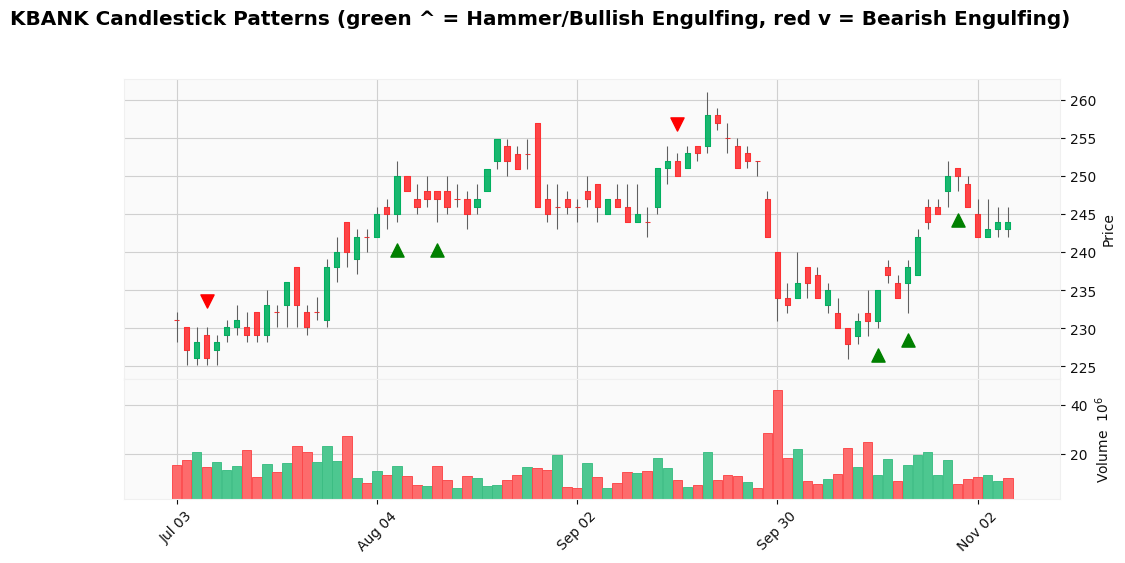

In [5]:
# กราฟแท่งเทียน 4 เดือนล่าสุด พร้อมลูกศรบอกรูปแบบ
d = data[STOCK].tail(84); pp = pat.loc[d.index]                         # 84 วันทำการ ≈ 4 เดือน
bull = np.where(pp["Bullish Engulfing"] | pp["Hammer"], d["Low"] * 0.985, np.nan)   # ลูกศรขึ้นใต้แท่ง
bear = np.where(pp["Bearish Engulfing"], d["High"] * 1.015, np.nan)                 # ลูกศรลงเหนือแท่ง
aps = []
if np.isfinite(bull).any():
    aps.append(mpf.make_addplot(bull, type="scatter", marker="^", markersize=90, color="green"))
if np.isfinite(bear).any():
    aps.append(mpf.make_addplot(bear, type="scatter", marker="v", markersize=90, color="red"))
mpf.plot(d, type="candle", style="yahoo", volume=True, addplot=aps, figsize=(13, 6),
         title=f"{STOCK} Candlestick Patterns (green ^ = Hammer/Bullish Engulfing, red v = Bearish Engulfing)")

### การวิเคราะห์แนวโน้มด้วย SMA และ EMA / Momentum ด้วย MACD / Overbought-Oversold ด้วย RSI / ความผันผวนด้วย Bollinger Bands

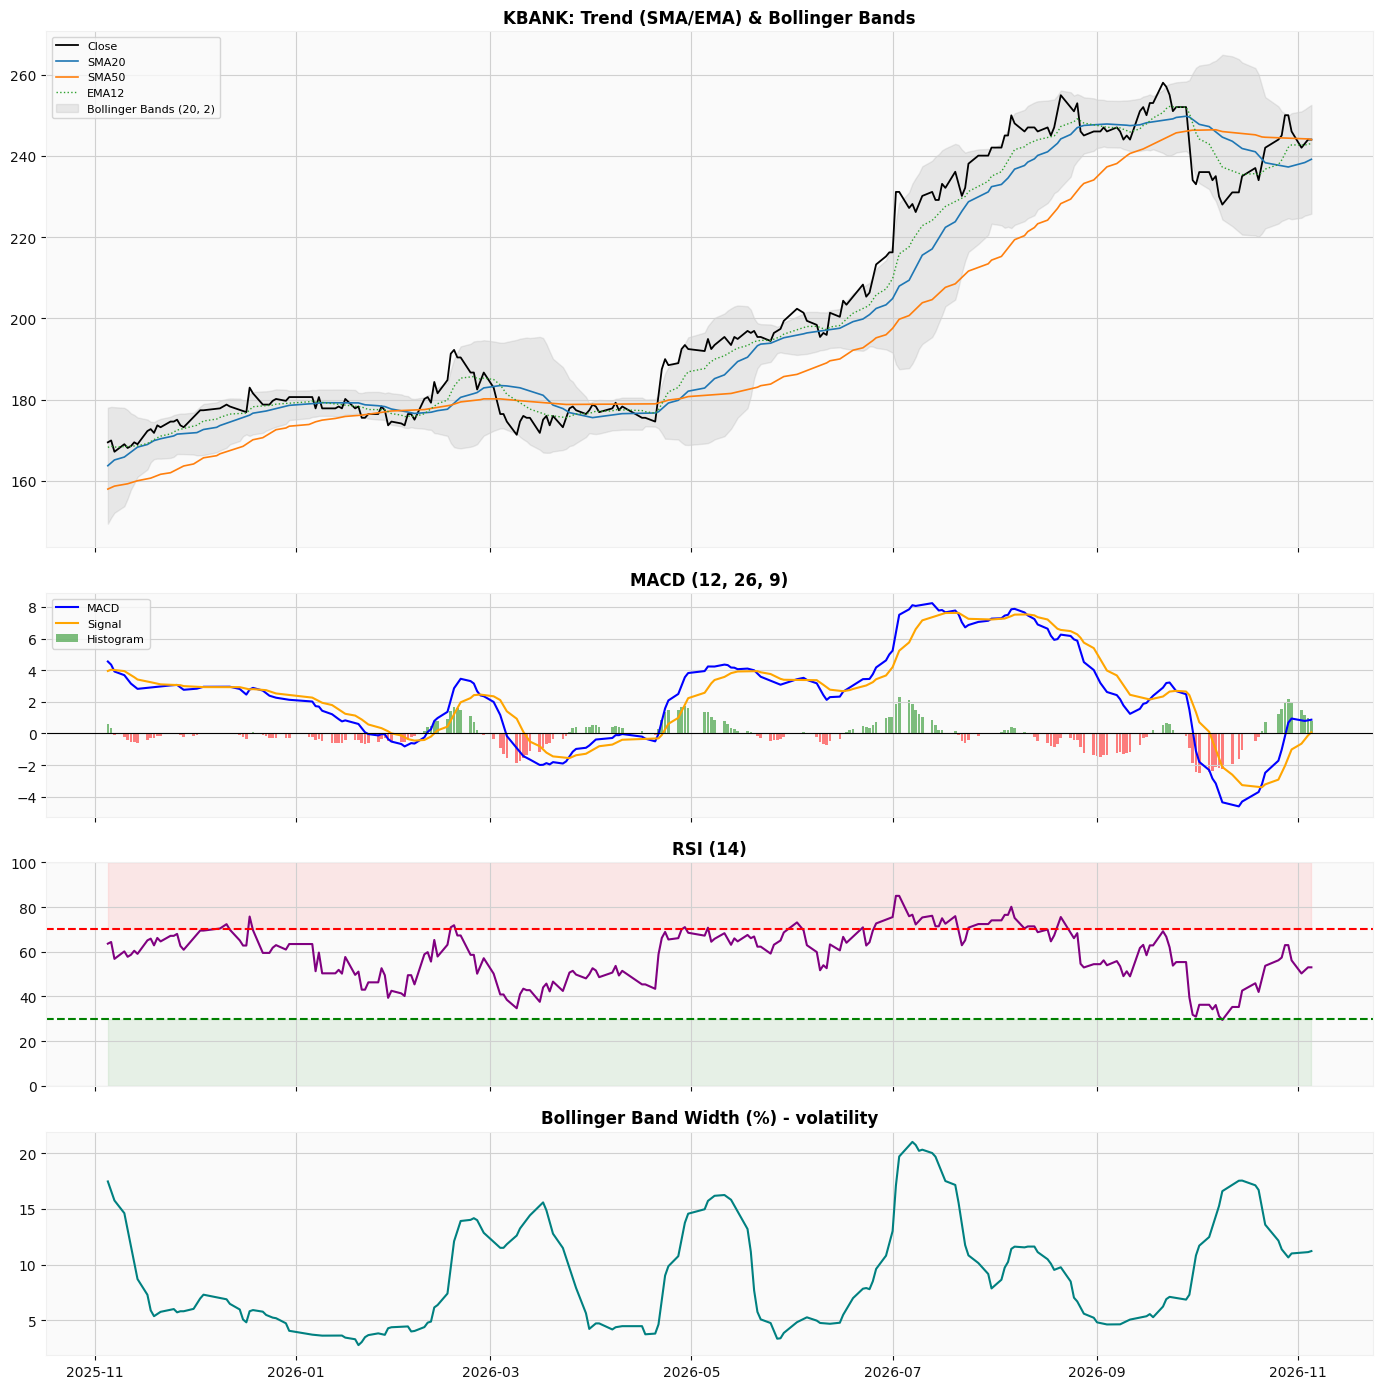

In [6]:
d = ind[STOCK].loc[TEST_START:]                                          # ช่วง 1 ปีล่าสุด
fig, axes = plt.subplots(4, 1, figsize=(14, 14), sharex=True, gridspec_kw={"height_ratios": [3, 1.3, 1.3, 1.3]})
# (1) ราคา + SMA/EMA + Bollinger Bands
axes[0].plot(d["Close"], label="Close", color="black", lw=1.3)
axes[0].plot(d["SMA20"], label="SMA20", lw=1.2); axes[0].plot(d["SMA50"], label="SMA50", lw=1.2)
axes[0].plot(d["EMA12"], label="EMA12", lw=1, ls=":")
axes[0].fill_between(d.index, d["BB_Low"], d["BB_Up"], color="grey", alpha=0.15, label="Bollinger Bands (20, 2)")   # แถบ BB
axes[0].set_title(f"{STOCK}: Trend (SMA/EMA) & Bollinger Bands", fontweight="bold"); axes[0].legend(loc="upper left", fontsize=8)
# (2) MACD
axes[1].plot(d["MACD"], label="MACD", color="blue"); axes[1].plot(d["Signal"], label="Signal", color="orange")
axes[1].bar(d.index, d["Hist"], color=np.where(d["Hist"] >= 0, "green", "red"), alpha=0.5, label="Histogram")  # เขียว = โมเมนตัมบวก
axes[1].axhline(0, color="black", lw=0.8); axes[1].set_title("MACD (12, 26, 9)", fontweight="bold"); axes[1].legend(loc="upper left", fontsize=8)
# (3) RSI
axes[2].plot(d["RSI"], color="purple")
axes[2].axhline(70, color="red", ls="--"); axes[2].axhline(30, color="green", ls="--")         # เส้น overbought/oversold
axes[2].fill_between(d.index, 70, 100, color="red", alpha=0.08); axes[2].fill_between(d.index, 0, 30, color="green", alpha=0.08)
axes[2].set_ylim(0, 100); axes[2].set_title("RSI (14)", fontweight="bold")
# (4) Bollinger Band Width
axes[3].plot(d["BB_Width"] * 100, color="teal"); axes[3].set_title("Bollinger Band Width (%) - volatility", fontweight="bold")
plt.tight_layout(); plt.show()

In [7]:
# สถานะทางเทคนิคล่าสุดของทั้ง 4 หุ้น (สรุปเป็นตาราง)
rows = []
for t in TICKERS:
    last = ind[t].iloc[-1]                                                # แถวล่าสุด
    rows.append({
        "Ticker": t, "Close": last["Close"],
        "Trend (SMA20 vs SMA50)": "Uptrend" if last["SMA20"] > last["SMA50"] else "Downtrend",
        "Price vs EMA12": "Above" if last["Close"] > last["EMA12"] else "Below",
        "MACD": "Bullish (>0)" if last["MACD"] > 0 else "Bearish (<0)",
        "RSI": round(last["RSI"], 1),
        "RSI Zone": "Overbought" if last["RSI"] > 70 else ("Oversold" if last["RSI"] < 30 else "Neutral"),
        "BB Position %": round((last["Close"] - last["BB_Low"]) / (last["BB_Up"] - last["BB_Low"]) * 100, 1),   # 0 = ขอบล่าง, 100 = ขอบบน
    })
pd.DataFrame(rows).set_index("Ticker")

,Close,Trend (SMA20 vs SMA50),Price vs EMA12,MACD,RSI,RSI Zone,BB Position %
Ticker,,,,,,,
KBANK,244.0000,Downtrend,Above,Bullish (>0),53.1000,Neutral,68.1000
CPALL,44.0000,Downtrend,Above,Bearish (<0),51.3000,Neutral,69.1000
OR,12.5000,Uptrend,Below,Bullish (>0),53.1000,Neutral,59.8000
AOT,60.5000,Downtrend,Above,Bearish (<0),52.8000,Neutral,76.0000


---
### เครื่องมือ Backtest (ใช้ร่วมกันทุกกลยุทธ์)
- `position` = 1 ถือหุ้น, 0 ถือเงินสด (Long-only ไม่ short)
- ใช้ `position.shift(1)` คือ **ส่งคำสั่งตามสัญญาณของวันนี้ แล้วได้ผลตอบแทนวันถัดไป** ป้องกัน look-ahead bias
- หักค่าคอมมิชชัน 0.15% ต่อการซื้อหรือขายแต่ละครั้ง
- เทียบกับ Buy & Hold ในช่วงเดียวกัน

In [8]:
FEE = 0.0015                                                              # ค่าคอม+VAT ประมาณ 0.15% ต่อครั้ง

def backtest(df, position):
    # df ต้องมีคอลัมน์ Return, position = Series 0/1 index เดียวกับ df
    pos = position.loc[TEST_START:].fillna(0)                             # ใช้เฉพาะช่วงทดสอบ
    ret = df["Return"].loc[pos.index].fillna(0)
    trades = pos.diff().abs().fillna(pos.iloc[0])                         # 1 = วันที่มีการซื้อหรือขาย
    strat = pos.shift(1).fillna(0) * ret - trades.shift(1).fillna(0) * FEE    # ผลตอบแทนกลยุทธ์หลังหักค่าคอม
    equity = (1 + strat).cumprod()                                        # มูลค่าเงินลงทุนสะสม (เริ่ม 1)
    bh = (1 + ret).cumprod()                                              # Buy & Hold
    # คิดผลแต่ละรอบการเทรด (ซื้อ -> ขาย) เพื่อหา win rate
    entries = pos[(pos.diff() == 1) | ((pos == 1) & (pos.index == pos.index[0]))].index
    exits = pos[pos.diff() == -1].index
    trade_rets = []
    for e in entries:
        x = exits[exits > e]
        end = x[0] if len(x) else pos.index[-1]                           # ถ้ายังไม่ขายให้ปิดที่วันสุดท้าย
        trade_rets.append(df["Close"].loc[end] / df["Close"].loc[e] - 1)
    vol = strat.std() * np.sqrt(TRADING_DAYS)
    stats = {
        "Total Return": equity.iloc[-1] - 1,
        "Buy & Hold": bh.iloc[-1] - 1,
        "Ann. Volatility": vol,
        "Sharpe": (strat.mean() * TRADING_DAYS - RF) / vol if vol > 0 else np.nan,
        "Max Drawdown": (equity / equity.cummax() - 1).min(),
        "# Trades": len(entries),
        "Win Rate": np.mean([r > 0 for r in trade_rets]) if trade_rets else np.nan,
        "Time in Market": pos.mean(),                                     # สัดส่วนวันที่ถือหุ้น
    }
    return equity, bh, stats

def plot_strategy(df, position, title, extra=None):
    d = df.loc[TEST_START:]; pos = position.loc[TEST_START:].fillna(0)
    first_buy = pos.index[:1] if pos.iloc[0] == 1 else pos.index[:0]      # ถ้าวันแรกของช่วงทดสอบถือหุ้นอยู่แล้ว ให้นับเป็นจุดซื้อ
    buys = first_buy.append(d.index[pos.diff() == 1])                     # จุดซื้อ
    sells = d.index[pos.diff() == -1]                                     # จุดขาย
    equity, bh, st = backtest(df, position)
    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
    axes[0].plot(d["Close"], color="black", lw=1.2, label="Close")
    if extra:                                                             # เส้น indicator ที่กลยุทธ์ใช้
        for col, style in extra.items():
            axes[0].plot(d[col], label=col, **style)
    axes[0].scatter(buys, d.loc[buys, "Close"], marker="^", s=120, color="green", zorder=5, label="BUY")
    axes[0].scatter(sells, d.loc[sells, "Close"], marker="v", s=120, color="red", zorder=5, label="SELL")
    axes[0].set_title(title, fontweight="bold"); axes[0].legend(loc="upper left", fontsize=8)
    axes[1].plot((equity - 1) * 100, label=f"Strategy ({st['Total Return']:+.1%})", color="blue")
    axes[1].plot((bh - 1) * 100, label=f"Buy & Hold ({st['Buy & Hold']:+.1%})", color="grey", ls="--")
    axes[1].axhline(0, color="black", lw=0.8); axes[1].set_ylabel("Cumulative return (%)"); axes[1].legend(loc="upper left")
    plt.tight_layout(); plt.show()
    return pd.Series(st, name=title)

---
## 4.2 SMA Crossover Strategy
**ตรรกะ:** เมื่อ SMA20 ตัดขึ้นเหนือ SMA50 (**Golden Cross**) แปลว่าแนวโน้มระยะสั้นแข็งแรงกว่าระยะกลาง → **ซื้อ** / เมื่อ SMA20 ตัดลงใต้ SMA50 (**Death Cross**) → **ขาย**

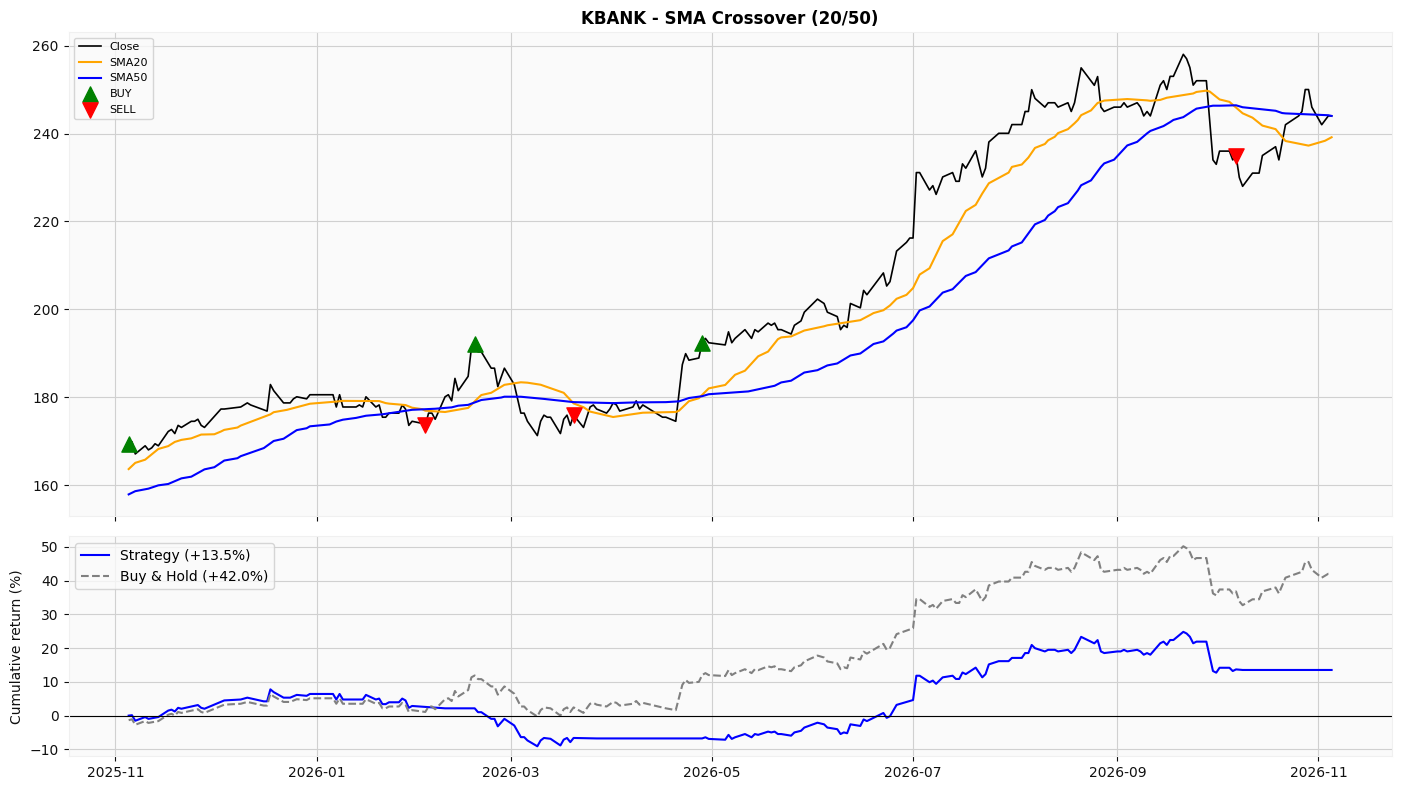

Total Return       0.1352
Buy & Hold         0.4203
Ann. Volatility    0.1725
Sharpe             0.7354
Max Drawdown      -0.1565
# Trades           3.0000
Win Rate           0.6667
Time in Market     0.7810
Name: KBANK - SMA Crossover (20/50), dtype: float64

In [9]:
def sma_crossover(df):
    return (df["SMA20"] > df["SMA50"]).astype(int)          # ถือเมื่อเส้นสั้นอยู่เหนือเส้นยาว

s1 = plot_strategy(ind[STOCK], sma_crossover(ind[STOCK]), f"{STOCK} - SMA Crossover (20/50)",
                   extra={"SMA20": {"color": "orange"}, "SMA50": {"color": "blue"}})
s1

---
## 4.3 RSI Reversal Strategy
**ตรรกะ (Mean reversion):** RSI ตัดขึ้นจากใต้ 30 (หลุดภาวะ Oversold) → **ซื้อ** / RSI ตัดลงจากเหนือ 70 (หลุดภาวะ Overbought) → **ขาย**

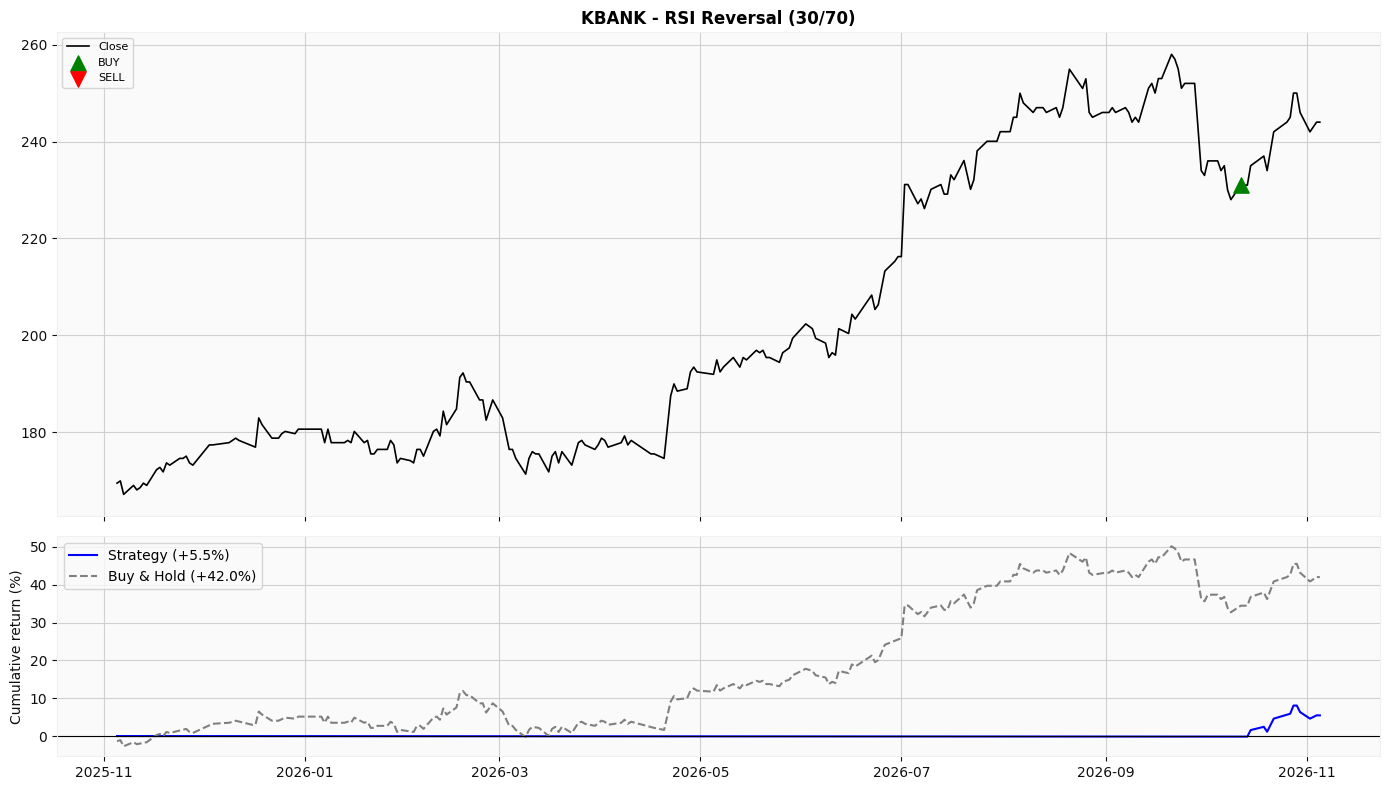

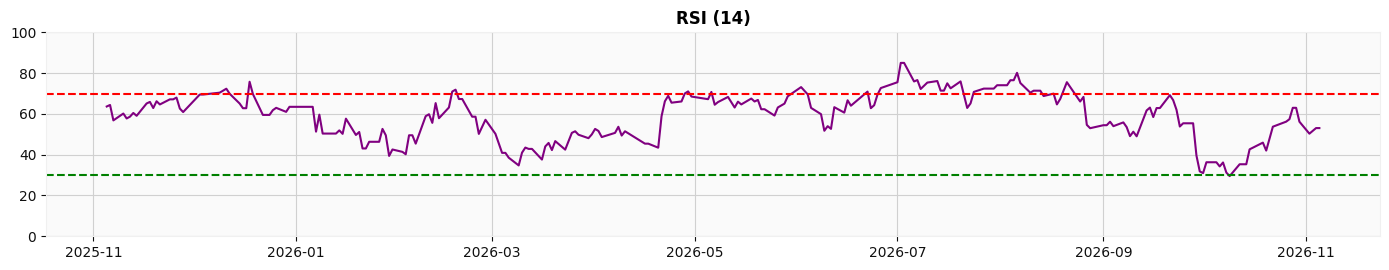

Total Return       0.0547
Buy & Hold         0.4203
Ann. Volatility    0.0475
Sharpe             0.7708
Max Drawdown      -0.0320
# Trades           1.0000
Win Rate           1.0000
Time in Market     0.0661
Name: KBANK - RSI Reversal (30/70), dtype: float64

In [10]:
def rsi_reversal(df, low=30, high=70):
    rsi = df["RSI"]
    buy = (rsi > low) & (rsi.shift() <= low)                # ตัดขึ้นผ่าน 30
    sell = (rsi < high) & (rsi.shift() >= high)             # ตัดลงผ่าน 70
    pos, holding = [], 0
    for b, s in zip(buy, sell):                             # วนทีละวันเพราะสถานะขึ้นกับวันก่อนหน้า
        if b: holding = 1
        elif s: holding = 0
        pos.append(holding)
    return pd.Series(pos, index=df.index)

s2 = plot_strategy(ind[STOCK], rsi_reversal(ind[STOCK]), f"{STOCK} - RSI Reversal (30/70)")
# แสดง RSI ประกอบ
d = ind[STOCK].loc[TEST_START:]
plt.figure(figsize=(14, 2.8)); plt.plot(d["RSI"], color="purple")
plt.axhline(70, color="red", ls="--"); plt.axhline(30, color="green", ls="--"); plt.ylim(0, 100)
plt.title("RSI (14)", fontweight="bold"); plt.tight_layout(); plt.show()
s2

---
## 4.4 MACD Zero Line Strategy
**ตรรกะ (Trend following):** MACD ตัดขึ้นเหนือเส้น 0 แปลว่า EMA12 > EMA26 โมเมนตัมเป็นบวก → **ซื้อ** / MACD ตัดลงใต้ 0 → **ขาย**

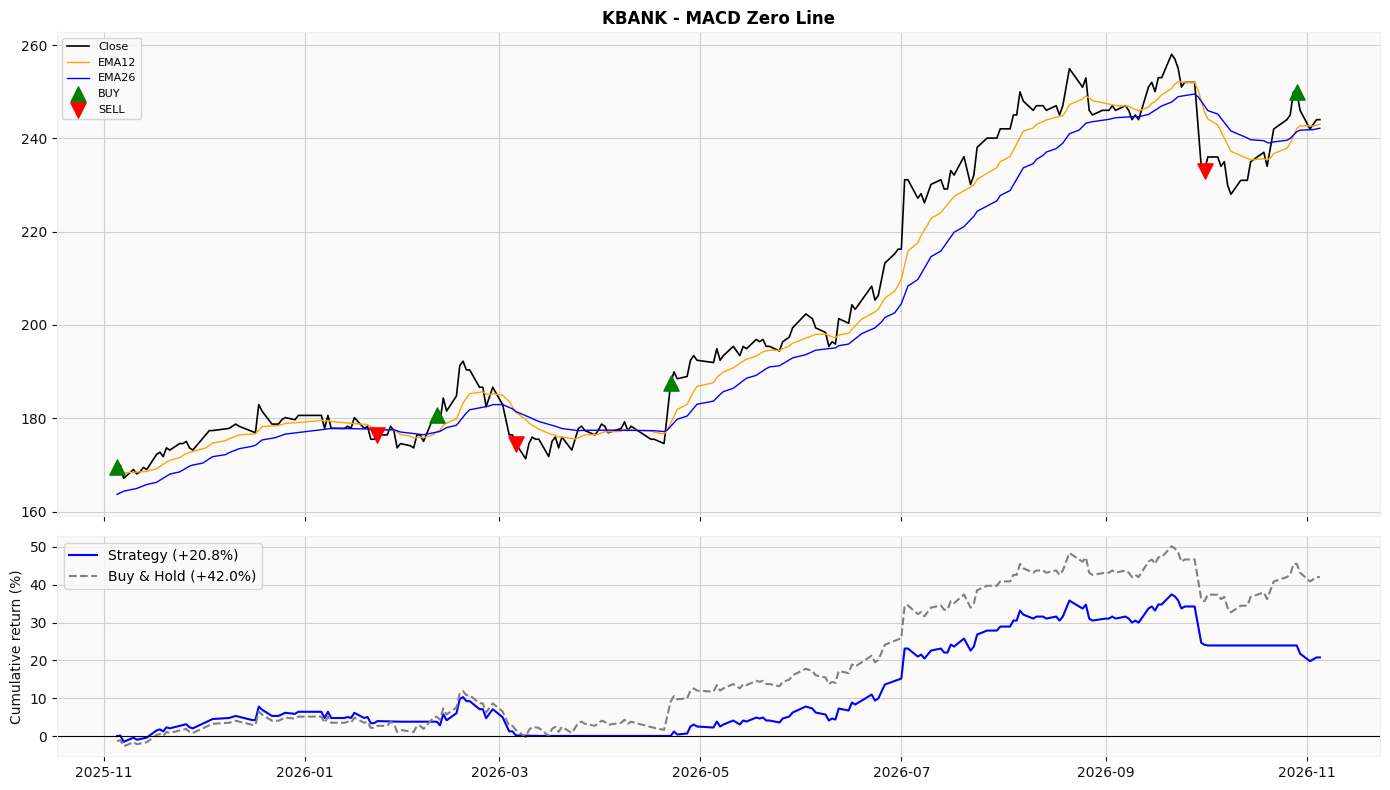

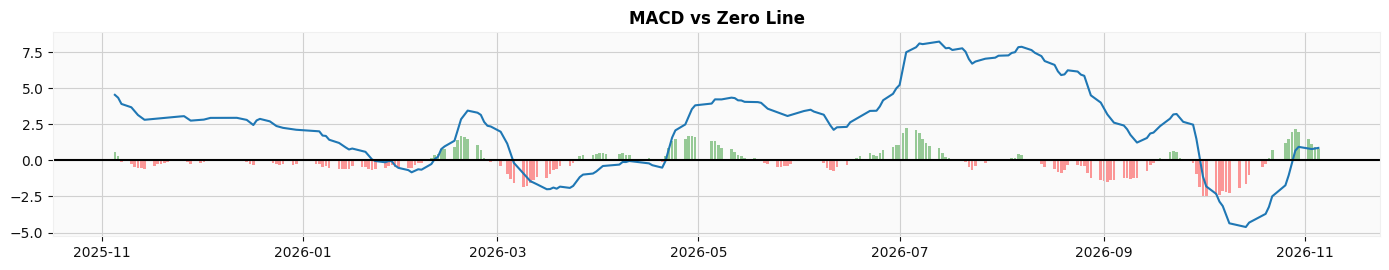

Total Return       0.2079
Buy & Hold         0.4203
Ann. Volatility    0.1752
Sharpe             1.0952
Max Drawdown      -0.1284
# Trades           4.0000
Win Rate           0.5000
Time in Market     0.7603
Name: KBANK - MACD Zero Line, dtype: float64

In [11]:
def macd_zero(df):
    return (df["MACD"] > 0).astype(int)                     # ถือเมื่อ MACD อยู่เหนือ 0

s3 = plot_strategy(ind[STOCK], macd_zero(ind[STOCK]), f"{STOCK} - MACD Zero Line",
                   extra={"EMA12": {"color": "orange", "lw": 1}, "EMA26": {"color": "blue", "lw": 1}})
d = ind[STOCK].loc[TEST_START:]
plt.figure(figsize=(14, 2.8)); plt.plot(d["MACD"], label="MACD"); plt.axhline(0, color="black")
plt.bar(d.index, d["Hist"], color=np.where(d["Hist"] >= 0, "green", "red"), alpha=0.4)
plt.title("MACD vs Zero Line", fontweight="bold"); plt.tight_layout(); plt.show()
s3

---
## 4.5 Bollinger Bands Breakout Strategy
**ตรรกะ (Breakout):** ราคาปิดทะลุขอบบน แปลว่ามีแรงซื้อแรงผิดปกติและความผันผวนกำลังขยาย → **ซื้อ** / ราคาปิดกลับลงใต้เส้นกลาง (SMA20) → **ขาย** (แรงส่งหมด)

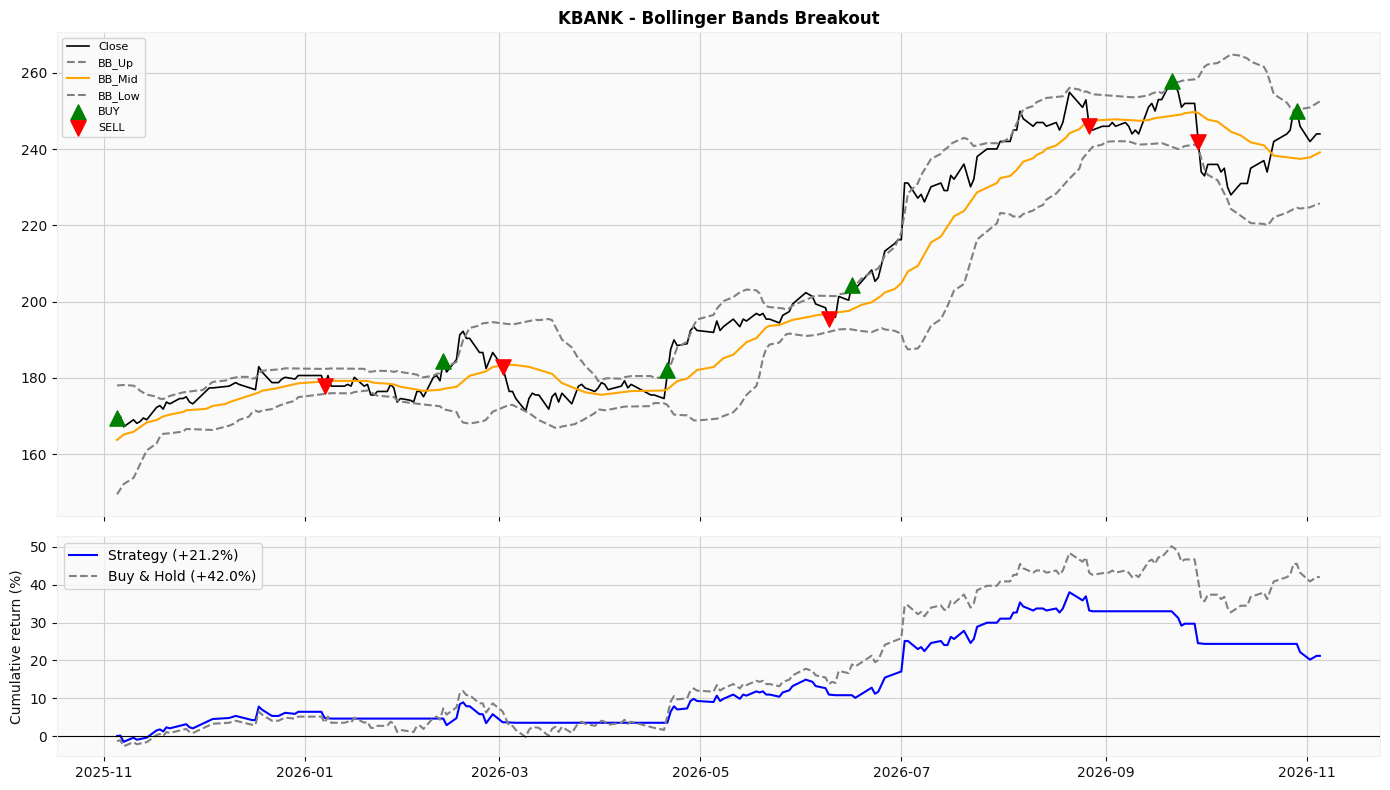

Total Return       0.2120
Buy & Hold         0.4203
Ann. Volatility    0.1549
Sharpe             1.2401
Max Drawdown      -0.1291
# Trades           6.0000
Win Rate           0.5000
Time in Market     0.5950
Name: KBANK - Bollinger Bands Breakout, dtype: float64

In [12]:
def bb_breakout(df):
    buy = df["Close"] > df["BB_Up"]                        # ทะลุขอบบน
    sell = df["Close"] < df["BB_Mid"]                      # หลุดเส้นกลาง
    pos, holding = [], 0
    for b, s in zip(buy, sell):
        if b: holding = 1
        elif s: holding = 0
        pos.append(holding)
    return pd.Series(pos, index=df.index)

s4 = plot_strategy(ind[STOCK], bb_breakout(ind[STOCK]), f"{STOCK} - Bollinger Bands Breakout",
                   extra={"BB_Up": {"color": "grey", "ls": "--"}, "BB_Mid": {"color": "orange"}, "BB_Low": {"color": "grey", "ls": "--"}})
s4

---
## 4.6 สรุปเปรียบเทียบกลยุทธ์ (ทุกหุ้น x ทุกกลยุทธ์)

In [13]:
STRATEGIES = {"SMA Crossover": sma_crossover, "RSI Reversal": rsi_reversal,
              "MACD Zero Line": macd_zero, "BB Breakout": bb_breakout}
results = []
for t in TICKERS:
    for name, fn in STRATEGIES.items():
        _, _, st = backtest(ind[t], fn(ind[t]))             # รันทุกกลยุทธ์กับทุกหุ้น
        results.append({"Ticker": t, "Strategy": name, **st})
res = pd.DataFrame(results).set_index(["Ticker", "Strategy"])
res["Excess vs B&H"] = res["Total Return"] - res["Buy & Hold"]   # ชนะ Buy & Hold กี่ %
fmt = {c: "{:.2%}" for c in ["Total Return", "Buy & Hold", "Ann. Volatility", "Max Drawdown", "Win Rate", "Time in Market", "Excess vs B&H"]}
res.style.format(fmt).format("{:.2f}", subset=["Sharpe"]).background_gradient(subset=["Excess vs B&H"], cmap="RdYlGn")

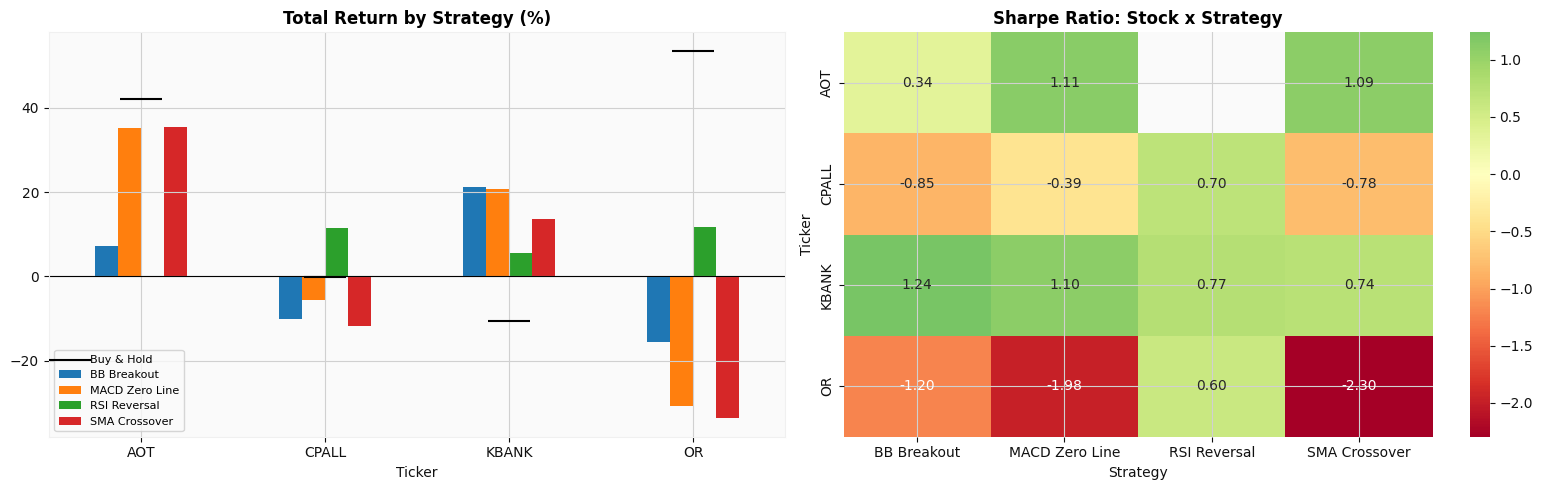

กลยุทธ์ที่ดีที่สุดของแต่ละหุ้น (ตาม Sharpe):


,Best Strategy
Ticker,
AOT,MACD Zero Line
CPALL,RSI Reversal
KBANK,BB Breakout
OR,RSI Reversal


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
res["Total Return"].unstack().mul(100).plot.bar(ax=axes[0], rot=0)               # ผลตอบแทนรวมแยกหุ้น/กลยุทธ์
axes[0].scatter(range(len(TICKERS)), res["Buy & Hold"].groupby(level=0).first().loc[TICKERS] * 100,
                marker="_", s=900, color="black", zorder=5, label="Buy & Hold")
axes[0].axhline(0, color="black", lw=0.8); axes[0].set_title("Total Return by Strategy (%)", fontweight="bold"); axes[0].legend(fontsize=8)
sns.heatmap(res["Sharpe"].unstack(), annot=True, fmt=".2f", cmap="RdYlGn", center=0, ax=axes[1])   # heatmap Sharpe
axes[1].set_title("Sharpe Ratio: Stock x Strategy", fontweight="bold")
plt.tight_layout(); plt.show()
print("กลยุทธ์ที่ดีที่สุดของแต่ละหุ้น (ตาม Sharpe):")
display(res["Sharpe"].groupby(level=0).idxmax().map(lambda x: x[1]).to_frame("Best Strategy"))

### สรุปส่วนที่ 4
- **Trend-following** (SMA Crossover, MACD Zero Line) ทำงานได้ดีในหุ้นที่มีแนวโน้มชัด แต่จะเสียเปรียบในตลาด sideway เพราะสัญญาณหลอก (whipsaw) และเข้า/ออกช้า
- **Mean-reversion** (RSI Reversal) เทรดน้อยครั้ง เหมาะกับหุ้นที่แกว่งในกรอบ แต่ในช่วงขาขึ้นแรงอาจขายเร็วเกินไป
- **Breakout** (Bollinger Bands) จับจังหวะที่ราคาเร่งตัว แต่เสี่ยงต่อ false breakout
- ไม่มีกลยุทธ์ใดชนะทุกหุ้น → ควรเลือกกลยุทธ์ให้เหมาะกับลักษณะของหุ้นแต่ละตัว และผลทดสอบย้อนหลัง 1 ปีไม่รับประกันผลในอนาคต (ควรทดสอบ out-of-sample เพิ่มเติม)